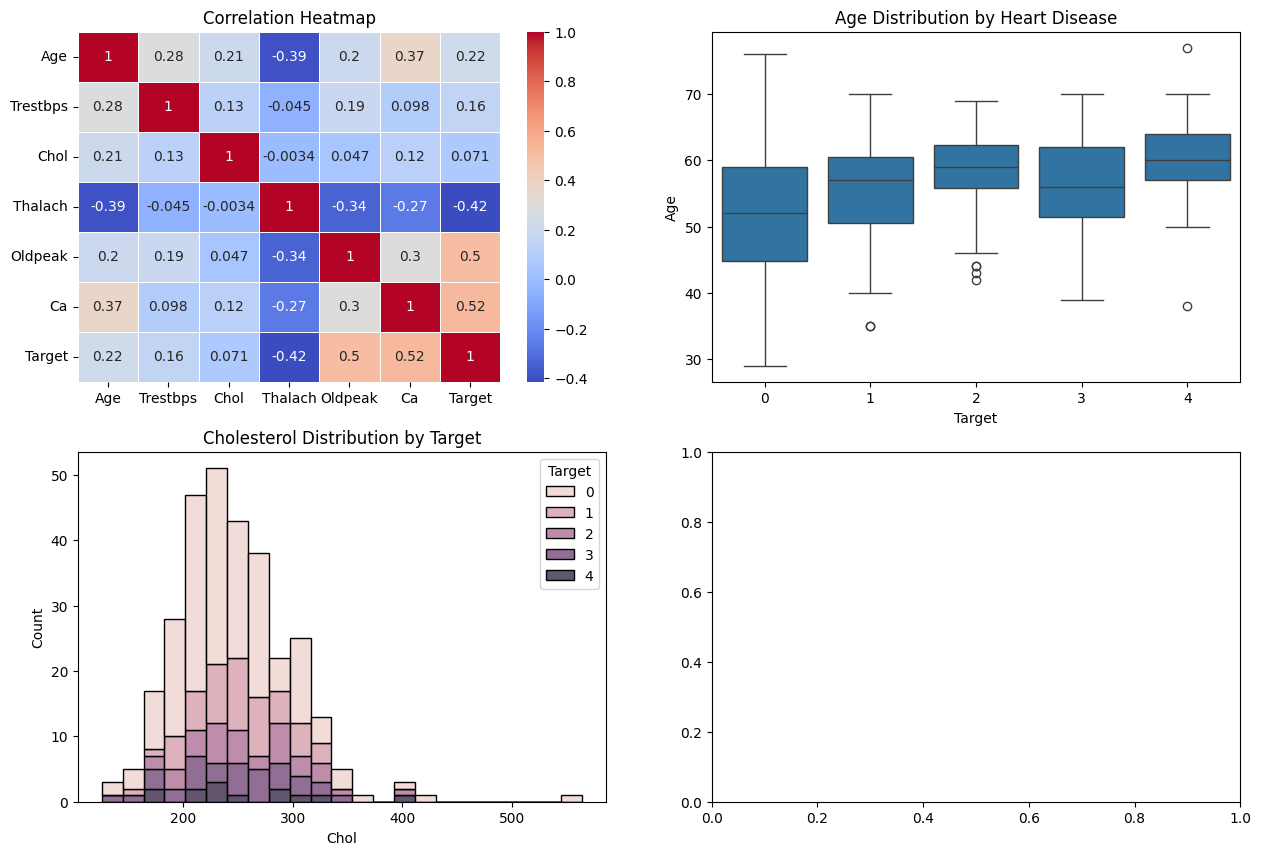

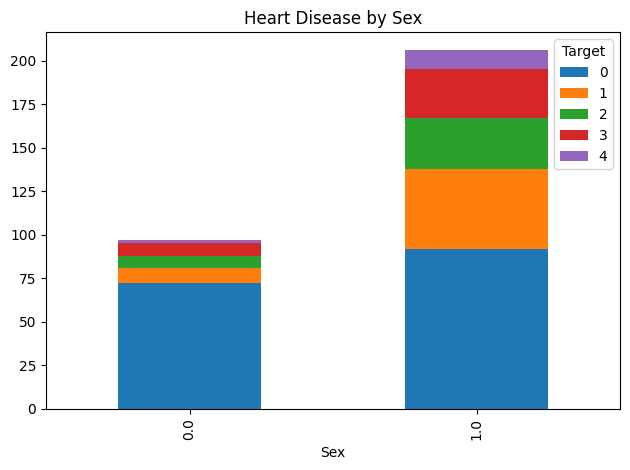

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.97      0.84        29
           1       0.09      0.08      0.09        12
           2       0.14      0.11      0.12         9
           3       0.00      0.00      0.00         7
           4       0.00      0.00      0.00         4

    accuracy                           0.49        61
   macro avg       0.19      0.23      0.21        61
weighted avg       0.39      0.49      0.43        61



C:\Users\INFINITYv\myproject\myenv\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\INFINITYv\myproject\myenv\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\INFINITYv\myproject\myenv\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


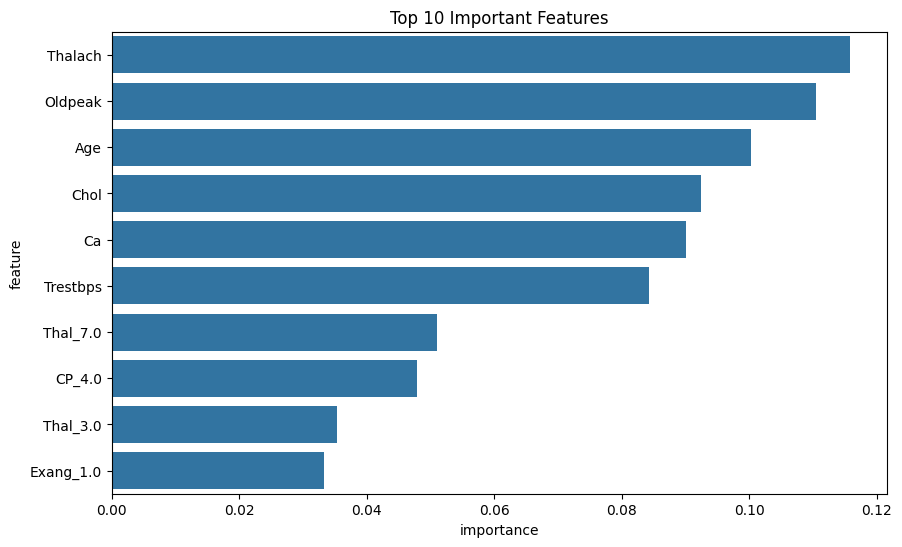

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Define column names
columns = [
    'Age', 'Sex', 'CP', 'Trestbps', 'Chol', 'Fbs', 'Restecg', 'Thalach', 
    'Exang', 'Oldpeak', 'Slope', 'Ca', 'Thal', 'Target'
]

# Load dataset with missing value handling
data = pd.read_csv('processed.cleveland.data', header=None, names=columns, na_values="?")

# Separate numeric and categorical columns
numeric_cols = ['Age', 'Trestbps', 'Chol', 'Thalach', 'Oldpeak', 'Ca']
int_cols = ['Sex', 'CP', 'Fbs', 'Restecg', 'Exang', 'Slope', 'Thal']
target_col = 'Target'

# Convert column types
for col in numeric_cols:
    data[col] = pd.to_numeric(data[col], errors='coerce')
for col in int_cols:
    data[col] = data[col].astype('category')

# Handle missing values
# For numeric columns, use median imputation
numeric_imputer = SimpleImputer(strategy='median')
data[numeric_cols] = numeric_imputer.fit_transform(data[numeric_cols])

# For categorical columns, use most frequent imputation
cat_imputer = SimpleImputer(strategy='most_frequent')
data[int_cols] = cat_imputer.fit_transform(data[int_cols])

# Exploratory Data Analysis and Visualizations
plt.figure(figsize=(15, 10))

# 1. Correlation Heatmap
plt.subplot(2, 2, 1)
correlation_matrix = data[numeric_cols + [target_col]].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap')

# 2. Age Distribution by Target
plt.subplot(2, 2, 2)
sns.boxplot(x=target_col, y='Age', data=data)
plt.title('Age Distribution by Heart Disease')

# 3. Distribution of Cholesterol
plt.subplot(2, 2, 3)
sns.histplot(data=data, x='Chol', hue=target_col, multiple='stack')
plt.title('Cholesterol Distribution by Target')

# 4. Sex Distribution
plt.subplot(2, 2, 4)
data.groupby(['Sex', target_col]).size().unstack().plot(kind='bar', stacked=True)
plt.title('Heart Disease by Sex')

plt.tight_layout()
plt.show()

# Prepare data for machine learning
X = data.drop(columns=[target_col])
y = data[target_col]

# Encode categorical variables
X = pd.get_dummies(X, columns=int_cols)

# Scale numeric features
scaler = StandardScaler()
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

# Make predictions
y_pred = rf_classifier.predict(X_test)

# Evaluation
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Feature Importance
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_classifier.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importance.head(10))
plt.title('Top 10 Important Features')
plt.show()

C:\Users\INFINITYv\myproject\myenv\Lib\site-packages\numpy\ma\core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


Best Parameters: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}

Optimized Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.91      0.87        33
           1       0.23      0.27      0.25        11
           2       0.00      0.00      0.00         7
           3       0.00      0.00      0.00         7
           4       0.00      0.00      0.00         3

    accuracy                           0.54        61
   macro avg       0.21      0.24      0.22        61
weighted avg       0.49      0.54      0.52        61



C:\Users\INFINITYv\myproject\myenv\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\INFINITYv\myproject\myenv\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\INFINITYv\myproject\myenv\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


<Figure size 1000x600 with 0 Axes>

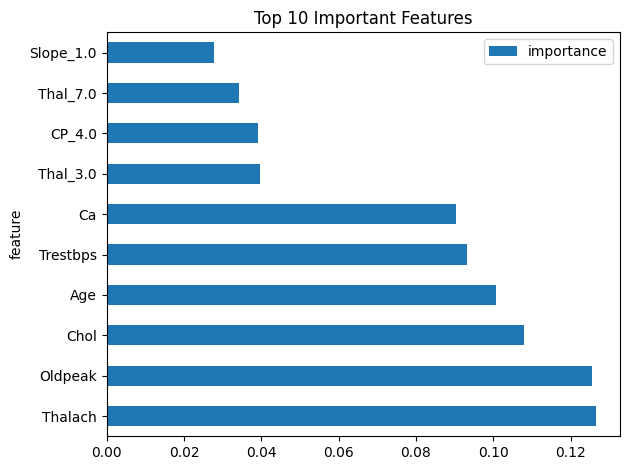

In [50]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Reload and preprocess data (using previous preprocessing steps)
columns = [
    'Age', 'Sex', 'CP', 'Trestbps', 'Chol', 'Fbs', 'Restecg', 'Thalach', 
    'Exang', 'Oldpeak', 'Slope', 'Ca', 'Thal', 'Target'
]

data = pd.read_csv('processed.cleveland.data', header=None, names=columns, na_values="?")

# Preprocessing
numeric_cols = ['Age', 'Trestbps', 'Chol', 'Thalach', 'Oldpeak', 'Ca']
int_cols = ['Sex', 'CP', 'Fbs', 'Restecg', 'Exang', 'Slope', 'Thal']
target_col = 'Target'

# Convert and impute
for col in numeric_cols:
    data[col] = pd.to_numeric(data[col], errors='coerce')
for col in int_cols:
    data[col] = data[col].astype('category')

numeric_imputer = SimpleImputer(strategy='median')
data[numeric_cols] = numeric_imputer.fit_transform(data[numeric_cols])

cat_imputer = SimpleImputer(strategy='most_frequent')
data[int_cols] = cat_imputer.fit_transform(data[int_cols])

# Prepare data for machine learning
X = data.drop(columns=[target_col])
y = data[target_col]

# Encode categorical variables
X = pd.get_dummies(X, columns=int_cols)

# Scale numeric features
scaler = StandardScaler()
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Hyperparameter tuning with GridSearchCV
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': [None, 'balanced']
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42), 
    param_grid, 
    cv=5, 
    scoring='f1_macro', 
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Best model
best_rf = grid_search.best_estimator_
print("Best Parameters:", grid_search.best_params_)

# Predictions with optimized model
y_pred = best_rf.predict(X_test)

# Classification Report
print("\nOptimized Classification Report:")
print(classification_report(y_test, y_pred))

# Feature Importance
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': best_rf.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
feature_importance.head(10).plot(x='feature', y='importance', kind='barh')
plt.title('Top 10 Important Features')
plt.tight_layout()
plt.show()

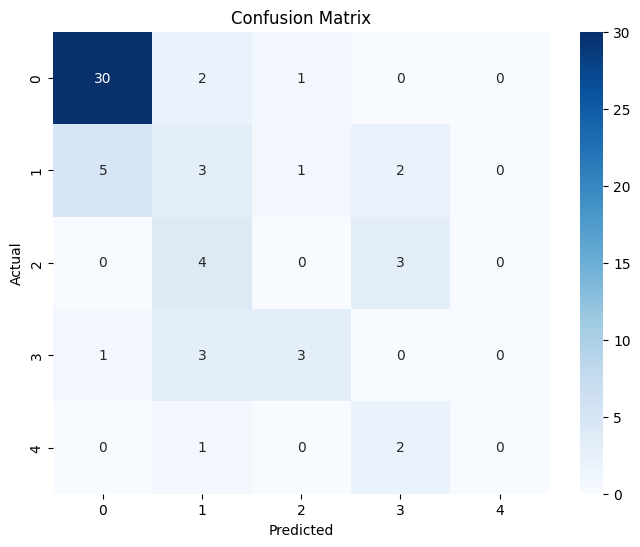

In [52]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1, 2, 3, 4], yticklabels=[0, 1, 2, 3, 4])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


In [54]:
# Check the distribution of the target classes
class_counts = y.value_counts()
print(class_counts)


Target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64
